# 神经网络的梯度

## 1.导入库、数据、模型参数设置

In [1]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn.functional as F

In [2]:
X_raw, Y_raw = make_moons(n_samples=10000, noise=0.1, random_state=1)
scaler = StandardScaler()
X_raw = scaler.fit_transform(X_raw)

batch =5
Cin = 2
Netron = 8
Cout = 1

X = X_raw[:batch].astype(np.float64)
Y = Y_raw[:batch].astype(np.float64)

print(f"{X.shape}\n{Y.shape}")

(5, 2)
(5,)


In [3]:
np.random.seed(1)
W1 = np.random.randn(Cin, Netron)*0.5
B1 = np.zeros((1, Netron))
W2 = np.random.randn(Netron, Cout)*0.5
B2 = np.zeros((1, Cout))

## 2.前向传播

In [4]:
# Linear
Z1 = X@W1 + B1
#ReLU
A1 = np.maximum(0, Z1)
# Linear
Z2 = A1@W2 + B2
# Sigmoid
A2 = 1 / (1 + np.exp(-Z2))


#------求二元交叉熵损失---------
eps = 1e-12
A2_clip = np.clip(A2, eps, 1-eps)
Y_col = Y.reshape(-1, 1)
L = -np.mean(Y_col * np.log(A2_clip) + (1 - Y_col) * np.log(1 - A2_clip))
print("Loss:", L)

Loss: 1.0183177578804683


## 3.定义梯度计算函数

In [5]:
def backward(X, Y, Z1, A1, Z2, A2, W1, B1, W2, B2):
    #统一Y形状为 (batch, 1)
    Y_col = Y.reshape(-1, 1)
    m = X.shape[0]  # batch size

    #Sigmoid+交叉熵
    eps = 1e-12
    A2_safe = np.clip(A2, eps, 1 - eps)

    # dL/dA2
    dl_da2 = - (Y_col / A2_safe - (1 - Y_col) / (1 - A2_safe)) / m

    # dA2/dZ2
    da2_dz2 = A2 * (1 - A2)

    # dL/dZ2 = dL/dA2 * dA2/dZ2  （化简后就是 (A2 - Y)/m）
    dl_dz2 = dl_da2 * da2_dz2

    #第二层线性层
    # dZ2/dA1 = W2
    dz2_da1 = W2

    # dL/dW2 = A1.T @ dL/dZ2
    dl_dw2 = A1.T @ dl_dz2

    # dL/dB2 = sum_i dL/dZ2_i
    dl_db2 = np.sum(dl_dz2, axis=0, keepdims=True)

    # dL/dA1 = dL/dZ2 @ W2.T
    dl_da1 = dl_dz2 @ dz2_da1.T

    #ReLU
    # dA1/dZ1
    da1_dz1 = (Z1 > 0).astype(np.float64)

    # dL/dZ1 = dL/dA1 * dA1/dZ1
    dl_dz1 = dl_da1 * da1_dz1

    #第一层线性层
    # dL/dW1 = X.T @ dL/dZ1
    dl_dw1 = X.T @ dl_dz1

    # dL/dB1 = sum_i dL/dZ1_i
    dl_db1 = np.sum(dl_dz1, axis=0, keepdims=True)

    return {
        "dW1": dl_dw1,
        "dB1": dl_db1,
        "dW2": dl_dw2,
        "dB2": dl_db2,
    }


## 4.调用autograd，输出两种方式的结果

In [6]:
X_t = torch.tensor(X, dtype=torch.float64)
Y_t = torch.tensor(Y, dtype=torch.float64).reshape(-1, 1)

W1_t = torch.tensor(W1, dtype=torch.float64).requires_grad_(True)
B1_t = torch.tensor(B1, dtype=torch.float64).requires_grad_(True)
W2_t = torch.tensor(W2, dtype=torch.float64).requires_grad_(True)
B2_t = torch.tensor(B2, dtype=torch.float64).requires_grad_(True)

In [7]:
Z1_t = X_t @ W1_t + B1_t
A1_t = torch.relu(Z1_t)
Z2_t = A1_t @ W2_t + B2_t
A2_t = torch.sigmoid(Z2_t)

L_t = F.binary_cross_entropy(A2_t, Y_t, reduction='mean')

print("Loss (NumPy)  :", L)
print("Loss (PyTorch):", L_t.item())
print("Loss 差异     :", abs(L - L_t.item()))

L_t.backward()

print("\n===== autograd 梯度 =====")
print("dW1 =\n", W1_t.grad)
print("\ndB1 =\n", B1_t.grad)
print("\ndW2 =\n", W2_t.grad)
print("\ndB2 =\n", B2_t.grad)

Loss (NumPy)  : 1.0183177578804683
Loss (PyTorch): 1.018317757880468
Loss 差异     : 2.220446049250313e-16

===== autograd 梯度 =====
dW1 =
 tensor([[ 0.0128,  0.2608, -0.0125, -0.0755,  0.0816, -0.3401, -0.0669, -0.1031],
        [ 0.0033, -0.0548,  0.0026, -0.0319,  0.0208,  0.0715, -0.0170, -0.0019]],
       dtype=torch.float64)

dB1 =
 tensor([[ 0.0074, -0.1498,  0.0072,  0.0231,  0.0470,  0.1954, -0.0385,  0.0523]],
       dtype=torch.float64)

dW2 =
 tensor([[-0.1265],
        [ 0.1662],
        [ 0.2482],
        [ 0.2517],
        [-0.0581],
        [ 0.6598],
        [-0.1508],
        [ 0.1603]], dtype=torch.float64)

dB2 =
 tensor([[0.2560]], dtype=torch.float64)


In [8]:
grads_np = backward(X, Y, Z1, A1, Z2, A2, W1, B1, W2, B2)

# autograd 梯度转 numpy
grads_torch = {
    "dW1": W1_t.grad.detach().numpy(),
    "dB1": B1_t.grad.detach().numpy(),
    "dW2": W2_t.grad.detach().numpy(),
    "dB2": B2_t.grad.detach().numpy(),
}


np.set_printoptions(precision=6, suppress=True, linewidth=120, threshold=np.inf)

print("===== 手写 backward vs autograd =====")
for name in ["dW1", "dB1", "dW2", "dB2"]:
    g_np = grads_np[name]
    g_pt = grads_torch[name]
    diff = np.max(np.abs(g_np - g_pt))
    print(f"\n{name}: numpy.shape={g_np.shape}, torch.shape={g_pt.shape}")
    print(f"  最大绝对误差 = {diff:.3e}")
    print("  numpy =\n", g_np)
    print("  torch =\n", g_pt)
    print("-" * 60)


===== 手写 backward vs autograd =====

dW1: numpy.shape=(2, 8), torch.shape=(2, 8)
  最大绝对误差 = 5.551e-17
  numpy =
 [[ 0.012788  0.260804 -0.012541 -0.07549   0.081626 -0.340087 -0.066866 -0.103084]
 [ 0.003256 -0.054809  0.002636 -0.031883  0.020782  0.071471 -0.017024 -0.001898]]
  torch =
 [[ 0.012788  0.260804 -0.012541 -0.07549   0.081626 -0.340087 -0.066866 -0.103084]
 [ 0.003256 -0.054809  0.002636 -0.031883  0.020782  0.071471 -0.017024 -0.001898]]
------------------------------------------------------------

dB1: numpy.shape=(1, 8), torch.shape=(1, 8)
  最大绝对误差 = 2.776e-17
  numpy =
 [[ 0.007363 -0.149838  0.007205  0.023096  0.046999  0.195388 -0.0385    0.052284]]
  torch =
 [[ 0.007363 -0.149838  0.007205  0.023096  0.046999  0.195388 -0.0385    0.052284]]
------------------------------------------------------------

dW2: numpy.shape=(8, 1), torch.shape=(8, 1)
  最大绝对误差 = 0.000e+00
  numpy =
 [[-0.126492]
 [ 0.166178]
 [ 0.248202]
 [ 0.251679]
 [-0.058094]
 [ 0.659788]
 [-0.1508

# 训练部分

In [9]:
# 训练数据
X_train = X_raw.astype(np.float64)               # (10000, 2)
Y_train = Y_raw.astype(np.float64).reshape(-1, 1)  # (10000, 1)

# 重新初始化参数
np.random.seed(42)
W1 = np.random.randn(Cin, Netron) * 0.5
B1 = np.zeros((1, Netron))
W2 = np.random.randn(Netron, Cout) * 0.5
B2 = np.zeros((1, Cout))

print("X_train.shape =", X_train.shape)
print("Y_train.shape =", Y_train.shape)

X_train.shape = (10000, 2)
Y_train.shape = (10000, 1)


In [10]:
# 超参数
lr = 0.1
epochs = 20
batch_size = 64

losses = []

for epoch in range(epochs):
    # 每个 epoch 打乱数据
    idx = np.random.permutation(len(X_train))
    X_shuf = X_train[idx]
    Y_shuf = Y_train[idx]

    epoch_loss = 0.0
    n_batches = 0

    for i in range(0, len(X_train), batch_size):
        # 取一个 mini-batch
        Xb = X_shuf[i:i + batch_size]      # (B, 2)
        Yb = Y_shuf[i:i + batch_size]      # (B, 1)

        #---- 前向传播 ----
        Z1 = Xb @ W1 + B1
        A1 = np.maximum(0, Z1)
        Z2 = A1 @ W2 + B2
        A2 = 1 / (1 + np.exp(-Z2))

        eps = 1e-12
        A2_clip = np.clip(A2, eps, 1 - eps)
        L = -np.mean(Yb * np.log(A2_clip) + (1 - Yb) * np.log(1 - A2_clip))

        #---- 反向传播 ----
        grads = backward(Xb, Yb, Z1, A1, Z2, A2, W1, B1, W2, B2)

        #---- SGD 更新 ----
        W1 -= lr * grads["dW1"]
        B1 -= lr * grads["dB1"]
        W2 -= lr * grads["dW2"]
        B2 -= lr * grads["dB2"]

        epoch_loss += L
        n_batches += 1

    avg_loss = epoch_loss / n_batches
    losses.append(avg_loss)

    if epoch % 20 == 0 or epoch == epochs - 1:
        print(f"Epoch {epoch:3d} | Loss = {avg_loss:.4f}")

print(f"\n训练结束，最终 Loss = {losses[-1]:.4f}")

Epoch   0 | Loss = 0.4396
Epoch  19 | Loss = 0.1868

训练结束，最终 Loss = 0.1868


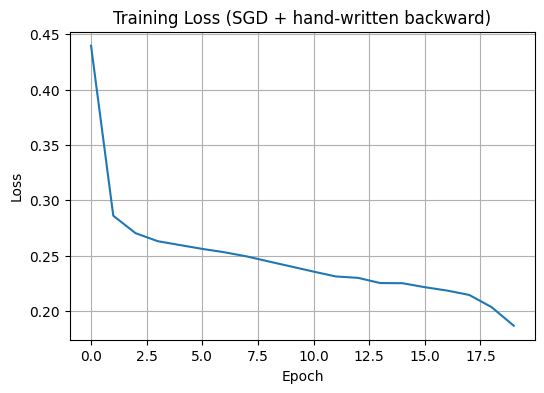

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss (SGD + hand-written backward)")
plt.grid(True)
plt.show()

## 测试精度

In [12]:
# 用训练好的参数在全体数据上前向一次
Z1 = X_train @ W1 + B1
A1 = np.maximum(0, Z1)
Z2 = A1 @ W2 + B2
A2 = 1 / (1 + np.exp(-Z2))

# 概率 > 0.5 判为 1
Y_pred = (A2 > 0.5).astype(np.float64)
acc = np.mean(Y_pred == Y_train)
print(f"训练集准确率: {acc:.4f}")

训练集准确率: 0.9224
